## Aprendizaje no Supervisado

Cruz, Pablo Danilo

Ricalde, Maximiliano Jeremias

Licenciatura en Análisis de Sistemas - Facultad de ciencias Exactas - UNSa -2026


## 0. Carga del DataSet y Librerias Necesarias

In [17]:
# --- Preparar el entorno: solo actúa si estás en Google Colab ---
import sys
import pandas as pd
from pathlib import Path

from src2.data import eliminar_columnas, imputar_media


import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from src2.features import rango_escenarios
from src2.split import aplanar_escenarios, separar_variables
from src2.unsupervised import (Detector, control_posicion, entrenar_fold, loso,
                               metricas, residualizar_tiempo)
RUTA = Path.cwd()
if not (RUTA / "datasets").exists():
    RUTA = RUTA.parent
sys.path.insert(0, str(RUTA / "Colab"))
BASE = RUTA / "datasets"


print("raíz:", RUTA)
print("leyendo CSVs...")
dfs = {
    "S0":     pd.read_csv(BASE / "datasetS0.csv"),
    "S1":     pd.read_csv(BASE / "datasetS1.csv"),
    "S1-alt": pd.read_csv(BASE / "datasetS1alt.csv"),
    "S2":     pd.read_csv(BASE / "datasetS2.csv"),
    "S3":     pd.read_csv(BASE / "datasetS3.csv"),
    "S4":     pd.read_csv(BASE / "datasetS4.csv"),
    "S5":     pd.read_csv(BASE / "datasetS5.csv"),
    "S6":     pd.read_csv(BASE / "datasetS6.csv"),
}

# Agregar el escenario a cada bloque antes de concatenar evita el
# DataFrame fragmentado que generaba el MultiIndex + reset_index.
df = (pd.concat(dfs, names=["escenario"])
      .reset_index(level="escenario")
      .reset_index(drop=True))
df = imputar_media(eliminar_columnas(df))
SEED = 42

raíz: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab
leyendo CSVs...


/tmp/ipykernel_1267528/214061224.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(level="escenario")


## 1. Eliminacion de Columnas y Separacion de Variables

In [2]:
# --- Cargar los ocho escenarios y separar X de la etiqueta ---
brutos = dfs
dfs = {k: eliminar_columnas(bloque) for k, bloque in brutos.items()}
X, Y = {}, {}
for k, bloque in dfs.items():
    X[k], Y[k] = separar_variables(bloque)

print("escenarios:", list(dfs))
print("features por escenario:", {k: v.shape[1] for k, v in X.items()})
print("filas por escenario:", {k: len(v) for k, v in X.items()})


escenarios: ['S0', 'S1', 'S1-alt', 'S2', 'S3', 'S4', 'S5', 'S6']
features por escenario: {'S0': 132, 'S1': 132, 'S1-alt': 132, 'S2': 132, 'S3': 132, 'S4': 132, 'S5': 132, 'S6': 132}
filas por escenario: {'S0': 1798, 'S1': 1798, 'S1-alt': 1792, 'S2': 1768, 'S3': 1800, 'S4': 1798, 'S5': 1800, 'S6': 1800}


In [3]:
# --- Representaciones: niveles, rango móvil y ventana de 20 s ---
X_rango = rango_escenarios(X)
X_ventana, Y_ventana = aplanar_escenarios(X, Y, 20)

print("niveles:", X["S1"].shape, "| rango:", X_rango["S1"].shape)
print("ventana:", X_ventana["S1"].shape, "| etiqueta:", Y_ventana["S1"].shape)

niveles: (1798, 132) | rango: (1798, 132)
ventana: (1779, 2640) | etiqueta: (1779,)


## 2. Pregunta y protocolo

¿Qué significa detectar sin etiquetas y cómo se mide sin engañarse?

**Métricas.** AUC, recall@5 (TPR al 5 % de FPR), recall y especificidad con el umbral calibrado, y filas marcadas.

**Invariantes.** El reductor y el umbral se ajustan solo con benigno de entrenamiento; el escenario de test no participa.

In [4]:
# --- Los ocho grupos del protocolo ---
resumen = pd.DataFrame({
    "filas": {k: len(Y[k]) for k in Y},
    "benignas": {k: int((Y[k] == 0).sum()) for k in Y},
    "ataques": {k: int((Y[k] == 1).sum()) for k in Y},
})
display(resumen)

print("folds LOSO:", len(resumen))

,filas,benignas,ataques
S0,1798,1798,0
S1,1798,885,913
S1-alt,1792,882,910
S2,1768,865,903
S3,1800,888,912
S4,1798,541,1257
S5,1800,459,1341
S6,1800,450,1350


folds LOSO: 8


## 3. Analisis de eleccion del K

Se elige `k` para KMeans por codo y silueta; para Birch y DBSCAN se elige una escala con la distancia al k-ésimo vecino. Los tres terminan en el mismo score: distancia al prototipo benigno más cercano.

,inercia,silueta
k,,
2,427264.981,0.318
3,326412.576,0.346
4,259027.546,0.355
5,198718.115,0.355
6,174215.633,0.385
7,159017.410,0.378
8,148406.061,0.307
9,134448.467,0.323
10,125107.103,0.306


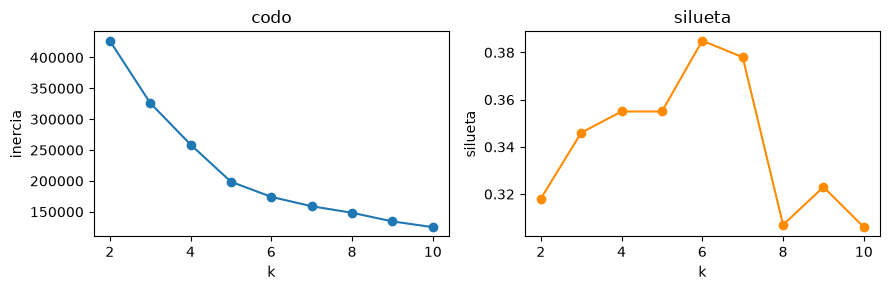

In [5]:
#  Codo y silueta para elegir k S1
X_fit, X_val = entrenar_fold(X_rango, Y, "S1")

preproceso = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PCA(n_components=0.95, random_state=SEED),
)
Z = preproceso.fit_transform(X_fit)

filas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    filas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": silhouette_score(Z, modelo.labels_, sample_size=min(2000, len(Z)), random_state=SEED),
    })
tabla_k = pd.DataFrame(filas).set_index("k").round(3)
display(tabla_k)

fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
ejes[0].plot(tabla_k.index, tabla_k["inercia"], marker="o")
ejes[0].set_xlabel("k")
ejes[0].set_ylabel("inercia")
ejes[0].set_title("codo")
ejes[1].plot(tabla_k.index, tabla_k["silueta"], marker="o", color="darkorange")
ejes[1].set_xlabel("k")
ejes[1].set_ylabel("silueta")
ejes[1].set_title("silueta")
plt.tight_layout()
plt.show()

## 4. Comparación de Modelos
Realizamos la detección de anomalias con K-Means, Birtch y DBScan modelos para ver cual trabaja mejor.

In [6]:

X_fit, X_val = entrenar_fold(X_rango, Y, "S1")
X_test = X_rango["S1"].reset_index(drop=True)
y_test = Y["S1"].to_numpy()

filas = []
for nombre in ("kmeans", "birch", "dbscan"):
    detector = Detector(nombre).fit(X_fit, X_val)
    fila = {"modelo": nombre}
    fila.update(metricas(y_test, detector.score(X_test), detector.umbral_))
    filas.append(fila)

tabla_s1 = pd.DataFrame(filas).set_index("modelo")
columnas = ["auc", "recall_5", "recall", "especificidad", "umbral", "flagged"]
display(tabla_s1[columnas].round(3))

,auc,recall_5,recall,especificidad,umbral,flagged
modelo,,,,,,
kmeans,0.748,0.294,0.289,0.959,10.748,300
birch,0.794,0.203,0.280,0.842,8.001,396
dbscan,0.803,0.188,0.280,0.897,7.850,347


## 5. Los ocho folds

 Deteccion y especificidad en 3 modelos kmeans, Birch y DBSCAN


In [7]:

filas = []
for modelo in ("kmeans", "birch", "dbscan"):
    filas.append(loso(X_rango, Y, modelo))

tabla_loso = pd.concat(filas, ignore_index=True)


auc = tabla_loso.pivot(index="escenario", columns="modelo", values="auc").reindex(list(X))
display(auc.round(3))


s0 = tabla_loso[tabla_loso["escenario"] == "S0"][["modelo", "especificidad", "flagged", "n"]]
display(s0.round(3))

resumen_loso = tabla_loso.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean()
display(resumen_loso.round(3))


modelo,birch,dbscan,kmeans
escenario,,,
S0,NaN,NaN,NaN
S1,0.794,0.803,0.748
S1-alt,0.488,0.494,0.478
S2,0.919,0.924,0.909
S3,0.626,0.598,0.531
S4,0.918,0.915,0.926
S5,0.912,0.917,0.867
S6,0.792,0.802,0.775


,modelo,especificidad,flagged,n
0,kmeans,0.934,119,1798
8,birch,1.000,0,1798
16,dbscan,1.000,0,1798


,auc,recall_5,recall,especificidad
modelo,,,,
birch,0.778,0.312,0.311,0.920
dbscan,0.779,0.331,0.316,0.925
kmeans,0.747,0.301,0.220,0.936


## 6. PCA

Se compara sin PCA, PCA al 95 % y un número fijo de componentes. 

In [8]:

filas = []
for varianza in (None, 0.95, 5, 10):
    tabla = loso(X_rango, Y, "kmeans", varianza=varianza)
    resumen = tabla.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean().iloc[0]
    filas.append({
        "PCA": "sin PCA" if varianza is None else str(varianza),
        "AUC": resumen["auc"],
        "recall@5": resumen["recall_5"],
        "recall": resumen["recall"],
        "espec S0": float(tabla.loc[tabla["escenario"] == "S0", "especificidad"].iloc[0]),
    })

comparacion_pca = pd.DataFrame(filas).set_index("PCA")
display(comparacion_pca.round(3))


,AUC,recall@5,recall,espec S0
PCA,,,,
sin PCA,0.761,0.321,0.344,0.950
0.95,0.747,0.301,0.220,0.934
5,0.666,0.209,0.111,0.730
10,0.746,0.303,0.167,0.935


## 7. Comparacion de las transformaciones empleadas en Supervisado
Aplicamos transformaciones de filas para poder reducir la fuga de datos. Debido a la cantidad de datos que tenemos y de la forma en la que fueron recopiladas, los datos pueden sufrir fuga de informacion. Varias columnas estan relacionas con el tiempo y el modelo llega a aprender esos patrones para detectar los ataques. 

- 

In [9]:

representaciones = {
    "niveles (crudo)": (X, Y),
    "rango móvil 120 s": (X_rango, Y),
    "ventana 20 s": (X_ventana, Y_ventana),
}

filas = []
for nombre, (X_rep, Y_rep) in representaciones.items():
    tabla = loso(X_rep, Y_rep, "birch")
    resumen = tabla.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean().iloc[0]
    filas.append({
        "representación": nombre,
        "features": X_rep["S1"].shape[1],
        "AUC": resumen["auc"],
        "recall@5": resumen["recall_5"],
        "recall": resumen["recall"],
        "espec S0": float(tabla.loc[tabla["escenario"] == "S0", "especificidad"].iloc[0]),
    })

comparacion_transformaciones = pd.DataFrame(filas).set_index("representación")
display(comparacion_transformaciones.round(3))


,features,AUC,recall@5,recall,espec S0
representación,,,,,
niveles (crudo),132,0.723,0.288,0.232,0.99
rango móvil 120 s,132,0.778,0.312,0.311,1.00
ventana 20 s,2640,0.693,0.329,0.238,0.99


## 8. ¿Que se esta Clusterizando?



In [10]:

X_all = pd.concat([X_rango[k] for k in X_rango], ignore_index=True)
y_all = np.concatenate([Y[k].to_numpy() for k in X_rango])
grupo_all = np.concatenate([np.full(len(X_rango[k]), k) for k in X_rango])
pos_all = np.concatenate([np.linspace(0, 1, len(X_rango[k])) for k in X_rango])


control = control_posicion(X_all, y_all, grupo_all)
display(control[["escenario", "auc_posicion", "r2_posicion"]].round(3))


X_sin_tiempo = residualizar_tiempo(X_all, pos_all, grupo_all)
X_sin_tiempo_dict = {
    k: X_sin_tiempo.loc[grupo_all == k].reset_index(drop=True)
    for k in X_rango
}

tabla_sin_tiempo = loso(X_sin_tiempo_dict, Y, "kmeans")

original = tabla_loso[tabla_loso["modelo"] == "kmeans"].set_index("escenario")
residual = tabla_sin_tiempo.set_index("escenario")
comparacion_tiempo = pd.DataFrame({
    "AUC original": original["auc"],
    "AUC sin tiempo": residual["auc"],
    "delta AUC": residual["auc"] - original["auc"],
    "recall@5 original": original["recall_5"],
    "recall@5 sin tiempo": residual["recall_5"],
    "espec S0 original": original["especificidad"],
    "espec S0 sin tiempo": residual["especificidad"],
})
display(comparacion_tiempo.round(3))


,escenario,auc_posicion,r2_posicion
0,S0,NaN,0.973
1,S1,0.771,0.983
2,S1-alt,0.815,0.986
3,S2,0.755,0.980
4,S3,0.662,0.981
5,S4,0.992,0.974
6,S5,0.987,0.980
7,S6,0.973,0.974


,AUC original,AUC sin tiempo,delta AUC,recall@5 original,recall@5 sin tiempo,espec S0 original,espec S0 sin tiempo
escenario,,,,,,,
S0,NaN,NaN,NaN,NaN,NaN,0.934,0.976
S1,0.748,0.695,-0.053,0.294,0.217,0.959,0.995
S1-alt,0.478,0.452,-0.026,0.007,0.000,0.747,0.808
S2,0.909,0.607,-0.301,0.607,0.000,0.979,0.753
S3,0.531,0.644,0.112,0.000,0.109,0.997,1.000
S4,0.926,0.596,-0.330,0.661,0.095,0.982,0.957
S5,0.867,0.781,-0.086,0.119,0.126,0.902,0.919
S6,0.775,0.696,-0.079,0.420,0.159,0.991,0.991


## 9. Clusterizacion de ataques

¿El clustering identifica familia o escenario, o solo recupera tiempo?

Primero se mira qué representan los grupos cuando se ajustan solo con benigno (regímenes de operación). Después, solo filas de ataque: KMeans con k=3 (familia) y k=8 (escenario); Birch y DBSCAN con su escala; ARI contra familia, escenario y fase, más la tabla de contingencia. Al final, una línea para el conjunto mezclado: cuánto separa ataque de benigno.


In [11]:
# === 6.1 Regímenes de operación: clustering solo con benigno ===
from sklearn.cluster import KMeans

FAMILIA = {
    "S1": "modbus", "S1-alt": "modbus", "S2": "modbus",
    "S3": "arp", "S4": "arp", "S5": "arp",
    "S6": "mqtt",
}

def preparar(X):
    """Imputa, escala y proyecta con PCA; solo para describir, no para predecir."""
    pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        PCA(n_components=0.95, random_state=SEED),
    )
    return pipe.fit_transform(X)

X_benigno = pd.concat([X_rango[k][Y[k] == 0] for k in X_rango], ignore_index=True)
Z_benigno = preparar(X_benigno)
etiquetas_benigno = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit_predict(Z_benigno)

grupo_benigno = np.concatenate([
    np.full(int((Y[k] == 0).sum()), k) for k in X_rango
])
tabla_benigno = pd.crosstab(
    pd.Series(etiquetas_benigno, name="cluster"),
    grupo_benigno,
)
display(tabla_benigno)


col_0,S0,S1,S1-alt,S2,S3,S4,S5,S6
cluster,,,,,,,,
0,119,119,111,119,119,119,119,119
1,685,203,354,17,42,25,0,12
2,474,244,223,297,288,102,62,49
3,9,55,31,31,32,11,27,20
4,511,264,163,401,407,284,251,250


In [12]:

from sklearn.cluster import Birch, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from src2.unsupervised import escala_vecinos

X_ataque = pd.concat([X_rango[k][Y[k] == 1] for k in X_rango], ignore_index=True)
escenario_ataque = np.concatenate([
    np.full(int((Y[k] == 1).sum()), k) for k in X_rango
])
familia_ataque = np.array([FAMILIA[s] for s in escenario_ataque])

def grupo_fase(p):
    p = str(p).lower()
    if "recon" in p:
        return "recon"
    if "phase_1" in p:
        return "phase_1"
    if "phase_2" in p:
        return "phase_2"
    if "price" in p:
        return "mqtt_price"
    if "attack_mqtt" in p or "impact" in p or "industroyer_active" in p:
        return "impact"
    return "otro"

fase_ataque = np.array([
    grupo_fase(p)
    for k in X_rango
    for p in brutos[k].loc[Y[k] == 1, "attack_phase"]
])

Z_ataque = preparar(X_ataque)

def etiquetas_modelo(Z, modelo, k=None):
    if modelo == "kmeans":
        return KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
    escala = escala_vecinos(Z)
    if modelo == "birch":
        return Birch(threshold=escala, n_clusters=None).fit_predict(Z)
    if modelo == "dbscan":
        return DBSCAN(eps=escala, min_samples=5).fit_predict(Z)
    raise ValueError(f"modelo desconocido: {modelo}")

filas = []
for modelo, k in (("kmeans", 3), ("kmeans", 8), ("birch", None), ("dbscan", None)):
    etiquetas = etiquetas_modelo(Z_ataque, modelo, k)
    filas.append({
        "modelo": modelo,
        "k": k if k is not None else len(np.unique(etiquetas)),
        "ARI familia": adjusted_rand_score(familia_ataque, etiquetas),
        "ARI escenario": adjusted_rand_score(escenario_ataque, etiquetas),
        "ARI fase": adjusted_rand_score(fase_ataque, etiquetas),
        "silhouette": silhouette_score(
            Z_ataque, etiquetas,
            sample_size=min(2000, len(Z_ataque)),
            random_state=SEED,
        ) if len(np.unique(etiquetas)) > 1 else np.nan,
    })

tabla_ataque = pd.DataFrame(filas).set_index(["modelo", "k"])
display(tabla_ataque.round(3))

# Contingencia del k=3 contra familia
etiquetas_k3 = etiquetas_modelo(Z_ataque, "kmeans", 3)
display(pd.crosstab(
    pd.Series(etiquetas_k3, name="cluster"),
    familia_ataque,
))


ARI familia  ARI escenario  ARI fase  silhouette
modelo k                                                    
kmeans 3          0.292          0.205     0.103       0.150
       8          0.100          0.164     0.065       0.199
birch  440        0.012          0.040     0.010       0.691
dbscan 479        0.008          0.029     0.008       0.656

col_0,arp,modbus,mqtt
cluster,,,
0,960,949,711
1,2364,66,283
2,186,1711,356


In [13]:

X_todo = pd.concat([X_rango[k] for k in X_rango], ignore_index=True)
y_todo = np.concatenate([Y[k].to_numpy() for k in X_rango])
grupo_todo = np.concatenate([np.full(len(X_rango[k]), k) for k in X_rango])
Z_todo = preparar(X_todo)

etiquetas_8 = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit_predict(Z_todo)
etiquetas_2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Z_todo)

resumen_mezclado = pd.DataFrame([
    {"comparación": "escenario (k=8)", "ARI": adjusted_rand_score(grupo_todo, etiquetas_8)},
    {"comparación": "ataque/benigno (k=2)", "ARI": adjusted_rand_score(y_todo, etiquetas_2)},
])
display(resumen_mezclado.round(3))


,comparación,ARI
0,escenario (k=8),0.083
1,ataque/benigno (k=2),0.160


### 9.5 Clustering sobre las 132 columnas crudas

Antes de reducir a invariantes, se repite el mismo análisis —búsqueda de K y comparación de modelos con las mismas métricas— sobre las **132 columnas crudas** (niveles). Mismo pipeline (imputar → RobustScaler → PCA 95 %)

In [18]:

X_crudo = pd.concat([X[k] for k in X], ignore_index=True)
y_crudo = np.concatenate([Y[k].to_numpy() for k in X])
escenario_crudo = np.concatenate([np.full(len(Y[k]), k) for k in X])

Z_crudo = make_pipeline(
    SimpleImputer(strategy="median"),
    RobustScaler(),
    PCA(n_components=0.95, random_state=SEED),
).fit_transform(X_crudo)

print("crudo:", X_crudo.shape, "| componentes PCA:", Z_crudo.shape[1])


crudo: (14354, 132) | componentes PCA: 1


,inercia,silueta,davies_bouldin,caida_%
k,,,,
2,2.375584e+10,1.000,0.014,NaN
3,7.278260e+09,0.995,0.355,69.4
4,4.125234e+09,0.994,0.435,43.3
5,2.287125e+09,0.995,0.469,44.6
6,1.366084e+09,0.994,0.424,40.3
7,8.977677e+08,0.996,0.416,34.3
8,6.028525e+08,0.996,0.353,32.8
9,4.102042e+08,0.996,0.355,32.0
10,3.310134e+08,0.996,0.347,19.3


K elegido sobre crudo (silueta): 2


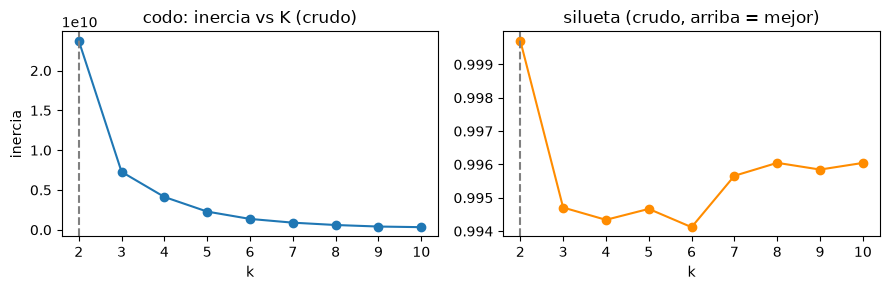

In [19]:

from sklearn.metrics import davies_bouldin_score

filas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_crudo)
    filas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": silhouette_score(Z_crudo, modelo.labels_, sample_size=3000, random_state=SEED),
        "davies_bouldin": davies_bouldin_score(Z_crudo, modelo.labels_),
    })
estudio_k_crudo = pd.DataFrame(filas).set_index("k")
estudio_k_crudo["caida_%"] = (-estudio_k_crudo["inercia"].diff()
                              / estudio_k_crudo["inercia"].shift(1) * 100).round(1)
display(estudio_k_crudo.round(3))

K_crudo = int(estudio_k_crudo["silueta"].idxmax())
print("K elegido sobre crudo (silueta):", K_crudo)

fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
ejes[0].plot(estudio_k_crudo.index, estudio_k_crudo["inercia"], marker="o")
ejes[0].axvline(K_crudo, color="gray", ls="--")
ejes[0].set_title("codo: inercia vs K (crudo)")
ejes[0].set_xlabel("k")
ejes[0].set_ylabel("inercia")
ejes[1].plot(estudio_k_crudo.index, estudio_k_crudo["silueta"], marker="o", color="darkorange")
ejes[1].axvline(K_crudo, color="gray", ls="--")
ejes[1].set_title("silueta (crudo, arriba = mejor)")
ejes[1].set_xlabel("k")
plt.tight_layout()
plt.show()


### Comparacion de Modelos

In [20]:

from sklearn.cluster import Birch, DBSCAN, KMeans
from src2.interpretationNS import resumen_clustering
from src2.unsupervised import escala_vecinos

escala_crudo = escala_vecinos(Z_crudo)
modelos_crudo = {
    "kmeans": KMeans(n_clusters=K_crudo, n_init=10, random_state=SEED),
    "birch": Birch(threshold=escala_crudo, n_clusters=None),
    "dbscan": DBSCAN(eps=escala_crudo, min_samples=5),
}
print("K (crudo):", K_crudo, "| escala Birch/DBSCAN:", round(escala_crudo, 3))

filas = []
for nombre, modelo in modelos_crudo.items():
    etiquetas_crudo = modelo.fit_predict(Z_crudo)
    fila = {"modelo": nombre}
    fila.update(resumen_clustering(Z_crudo, etiquetas_crudo, y_crudo, escenario_crudo,
                                   "ataque", "escenario", random_state=SEED))
    filas.append(fila)
comparacion_crudo = pd.DataFrame(filas).set_index("modelo").round(3)
display(comparacion_crudo)

solidos_crudo = comparacion_crudo[comparacion_crudo["peso_min"] >= 0.01]
mejor_crudo = solidos_crudo["silueta"].idxmax()
print(f"mejor clustering sobre crudo: {mejor_crudo} "
      f"(silueta {comparacion_crudo.loc[mejor_crudo, 'silueta']:.3f}, "
      f"Davies-Bouldin {comparacion_crudo.loc[mejor_crudo, 'davies_bouldin']:.3f})")


K (crudo): 2 | escala Birch/DBSCAN: 0.003


,clusters,peso_min,silueta,calinski_harabasz,davies_bouldin,ARI ataque,ARI escenario,NMI ataque,NMI escenario
modelo,,,,,,,,,
kmeans,2,0.016,1.000,4.654093e+07,0.014,0.005,0.000,0.032,0.002
birch,787,0.000,0.592,3.136527e+16,0.252,0.001,0.006,0.057,0.217
dbscan,250,0.000,0.274,3.494600e+01,1.633,0.004,0.009,0.037,0.121


mejor clustering sobre crudo: kmeans (silueta 1.000, Davies-Bouldin 0.014)


### Interpretacion de Variables mas significativas

In [21]:

from src2.interpretationNS import perfil_clusters, tabla_clusters_escenario

km_crudo = KMeans(n_clusters=K_crudo, n_init=10, random_state=SEED).fit(Z_crudo)
etiquetas_km_crudo = km_crudo.labels_

display(perfil_clusters(X_crudo.to_numpy(dtype=float), etiquetas_km_crudo,
                        X_crudo.columns, top=5))
display(tabla_clusters_escenario(etiquetas_km_crudo, escenario_crudo))


,cluster,n,peso,variable,z
0,0,14123,0.984,Load-A-AC-Meter.cos_phi3,0.1
1,0,14123,0.984,Load-A-AC-Meter.cos_phi1,0.1
2,0,14123,0.984,Load-B-AC-Meter.cos_phi1,0.1
3,0,14123,0.984,Load-B-AC-Meter.cos_phi3,0.1
4,0,14123,0.984,Load-A-AC-Meter.cos_phi2,0.1
5,1,231,0.016,Load-A-AC-Meter.cos_phi3,-7.8
6,1,231,0.016,Load-A-AC-Meter.cos_phi1,-7.8
7,1,231,0.016,Load-B-AC-Meter.cos_phi1,-6.1
8,1,231,0.016,Load-B-AC-Meter.cos_phi3,-6.1
9,1,231,0.016,Load-A-AC-Meter.cos_phi2,-5.1


escenario,S0,S1,S1-alt,S2,S3,S4,S5,S6
cluster,,,,,,,,
0,1789,1739,1761,1737,1768,1776,1773,1780
1,9,59,31,31,32,22,27,20


In [22]:

from src2.interpretationNS import perfil_clusters

for k in range(2, 7):
    etiquetas_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z_crudo)
    silueta_k = silhouette_score(Z_crudo, etiquetas_k, sample_size=3000, random_state=SEED)
    print(f"\n===== K={k} | silueta={silueta_k:.3f} =====")
    display(perfil_clusters(X_crudo.to_numpy(dtype=float), etiquetas_k,
                            X_crudo.columns, top=2))



===== K=2 | silueta=1.000 =====


,cluster,n,peso,variable,z
0,0,14123,0.984,Load-A-AC-Meter.cos_phi3,0.1
1,0,14123,0.984,Load-A-AC-Meter.cos_phi1,0.1
2,1,231,0.016,Load-A-AC-Meter.cos_phi3,-7.8
3,1,231,0.016,Load-A-AC-Meter.cos_phi1,-7.8



===== K=3 | silueta=0.995 =====


,cluster,n,peso,variable,z
0,0,14123,0.984,Load-A-AC-Meter.cos_phi3,0.1
1,0,14123,0.984,Load-A-AC-Meter.cos_phi1,0.1



===== K=4 | silueta=0.994 =====


,cluster,n,peso,variable,z
0,0,14123,0.984,Load-A-AC-Meter.cos_phi3,0.1
1,0,14123,0.984,Load-A-AC-Meter.cos_phi1,0.1



===== K=5 | silueta=0.995 =====


,cluster,n,peso,variable,z
0,0,14123,0.984,Load-A-AC-Meter.cos_phi3,0.1
1,0,14123,0.984,Load-A-AC-Meter.cos_phi1,0.1



===== K=6 | silueta=0.994 =====


,cluster,n,peso,variable,z
0,0,14123,0.984,Load-A-AC-Meter.cos_phi3,0.1
1,0,14123,0.984,Load-A-AC-Meter.cos_phi1,0.1


### 10 Clustering buscando cumplir leyes fisicas 

Se clusteriza el dataset completo (8 escenarios, benignos y ataques) con invariantes que quitan el nivel absoluto y dejan la física. El K se elige por codo (inercia) y silueta; después se comparan KMeans, Birch y DBSCAN por métricas de clustering.

In [23]:

from sklearn.preprocessing import RobustScaler

MEDIDORES = ["BSS-Inverter-AC-Meter", "Load-A-AC-Meter", "Load-B-AC-Meter",
             "PV-Inverter-AC-Meter", "Substation-AC-Meter"]
RAMAS = [m for m in MEDIDORES if m != "Substation-AC-Meter"]


def invariantes_fisicas(df):
    """Invariantes intra-medidor (ΔSOC, S_error, imbalance) + balance nodal (P, Q)."""
    inv = pd.DataFrame(index=df.index)
    inv["dsoc"] = (df["Battery-SOC-Reported.soc_value"]
                   - df["Battery-SOC-Reference.soc_value"]).abs()
    for medidor in MEDIDORES:
        p = df[f"{medidor}.p_sum3"]
        q = df[f"{medidor}.q_sum3"]
        s = df[f"{medidor}.s_sum3"]
        inv[f"{medidor}__serror"] = np.sqrt(p**2 + q**2) - s
        fases = [df[f"{medidor}.uln1"], df[f"{medidor}.uln2"], df[f"{medidor}.uln3"]]
        pares = [(fases[i] - fases[j]).abs() for i in range(3) for j in range(i + 1, 3)]
        inv[f"{medidor}__imbalance"] = pd.concat(pares, axis=1).max(axis=1)
    inv["balance_p"] = (df["Substation-AC-Meter.p_sum3"]
                        - sum(df[f"{m}.p_sum3"] for m in RAMAS))
    inv["balance_q"] = (df["Substation-AC-Meter.q_sum3"]
                        - sum(df[f"{m}.q_sum3"] for m in RAMAS))
    return inv


X_inv = pd.concat([invariantes_fisicas(X[k]) for k in X], ignore_index=True)
y_inv = np.concatenate([Y[k].to_numpy() for k in X])
escenario_inv = np.concatenate([np.full(len(Y[k]), k) for k in X])

Z_inv = make_pipeline(
    SimpleImputer(strategy="median"),
    RobustScaler(),
    PCA(n_components=0.95, random_state=SEED),
).fit_transform(X_inv)

print("invariantes:", X_inv.shape, "| filas con ataque:", int(y_inv.sum()))


invariantes: (14354, 13) | filas con ataque: 7586


,inercia,silueta,davies_bouldin,caida_%
k,,,,
2,1.899835e+12,0.920,0.158,NaN
3,1.023748e+11,0.971,0.117,94.6
4,6.965177e+10,0.944,0.367,32.0
5,5.017351e+10,0.936,0.445,28.0
6,3.544784e+10,0.943,0.451,29.3
7,2.390519e+10,0.945,0.417,32.6
8,1.929966e+10,0.943,0.405,19.3
9,1.560394e+10,0.941,0.419,19.1
10,1.325839e+10,0.939,0.436,15.0


K elegido (silueta): 3


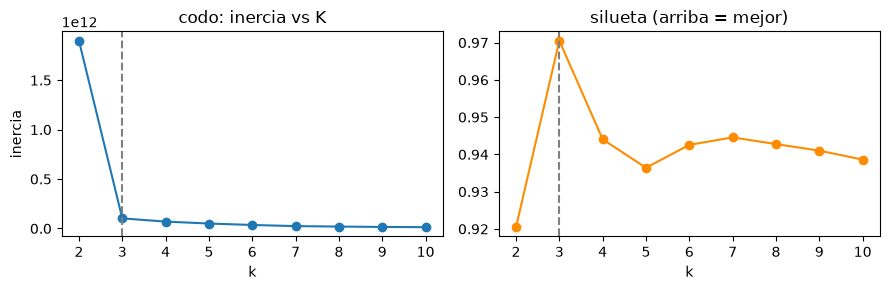

In [24]:

from sklearn.metrics import davies_bouldin_score

filas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_inv)
    filas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": silhouette_score(Z_inv, modelo.labels_, sample_size=3000, random_state=SEED),
        "davies_bouldin": davies_bouldin_score(Z_inv, modelo.labels_),
    })

estudio_k = pd.DataFrame(filas).set_index("k")
estudio_k["caida_%"] = (-estudio_k["inercia"].diff() / estudio_k["inercia"].shift(1) * 100).round(1)
display(estudio_k.round(3))

K = int(estudio_k["silueta"].idxmax())
print("K elegido (silueta):", K)


fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
ejes[0].plot(estudio_k.index, estudio_k["inercia"], marker="o")
ejes[0].axvline(K, color="gray", ls="--")
ejes[0].set_title("codo: inercia vs K")
ejes[0].set_xlabel("k")
ejes[0].set_ylabel("inercia")
ejes[1].plot(estudio_k.index, estudio_k["silueta"], marker="o", color="darkorange")
ejes[1].axvline(K, color="gray", ls="--")
ejes[1].set_title("silueta (arriba = mejor)")
ejes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

### 10.1 Comparacion de Modelos(Kmeans,Birch,DBSCAN)

In [25]:

from sklearn.cluster import Birch, DBSCAN, KMeans
from src2.interpretationNS import resumen_clustering
from src2.unsupervised import escala_vecinos

escala = escala_vecinos(Z_inv)      

modelos = {
    "kmeans": KMeans(n_clusters=K, n_init=10, random_state=SEED),
    "birch": Birch(threshold=escala, n_clusters=None),
    "dbscan": DBSCAN(eps=escala, min_samples=5),
}
print("K de KMeans:", K, "| escala Birch/DBSCAN:", round(escala, 3))

filas = []
for nombre, modelo in modelos.items():
    etiquetas = modelo.fit_predict(Z_inv)
    fila = {"modelo": nombre}
    fila.update(resumen_clustering(Z_inv, etiquetas, y_inv, escenario_inv,
                                   "ataque", "escenario", random_state=SEED))
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index("modelo").round(3)
display(comparacion)


solidos = comparacion[comparacion["peso_min"] >= 0.01]
mejor = solidos["silueta"].idxmax()
print(f"mejor clustering: {mejor} (silueta {comparacion.loc[mejor, 'silueta']:.3f}, "
      f"Davies-Bouldin {comparacion.loc[mejor, 'davies_bouldin']:.3f})")

K de KMeans: 3 | escala Birch/DBSCAN: 0.005


,clusters,peso_min,silueta,calinski_harabasz,davies_bouldin,ARI ataque,ARI escenario,NMI ataque,NMI escenario
modelo,,,,,,,,,
kmeans,3,0.042,0.971,3.766878e+05,0.117,0.029,0.036,0.163,0.204
birch,828,0.000,0.630,9.093172e+14,0.122,0.001,0.007,0.085,0.246
dbscan,394,0.000,0.202,1.285994e+05,1.824,0.033,0.036,0.112,0.259


mejor clustering: kmeans (silueta 0.971, Davies-Bouldin 0.117)


### 10.2 Interpetracion de Cluster con Z-score

In [26]:

from src2.interpretationNS import perfil_clusters, tabla_clusters_escenario

etiquetas = modelos[mejor].labels_

if -1 in etiquetas:
    print("filas de ruido (DBSCAN):", int((etiquetas == -1).sum()))

display(perfil_clusters(X_inv.to_numpy(dtype=float), etiquetas, X_inv.columns))

# Qué escenario cae en cada cluster: la lectura física se apoya en esto.
display(tabla_clusters_escenario(etiquetas, escenario_inv))

,cluster,n,peso,variable,z
0,0,12389,0.863,PV-Inverter-AC-Meter · residuo de potencia apa...,-0.2
1,0,12389,0.863,balance_p,-0.1
2,0,12389,0.863,PV-Inverter-AC-Meter · desequilibrio de fase,-0.1
3,1,602,0.042,Load-A-AC-Meter · residuo de potencia aparente,3.9
4,1,602,0.042,Load-B-AC-Meter · residuo de potencia aparente,3.4
5,1,602,0.042,balance_p,-2.7
6,2,1363,0.095,PV-Inverter-AC-Meter · residuo de potencia apa...,2.5
7,2,1363,0.095,balance_p,2.3
8,2,1363,0.095,Load-A-AC-Meter · residuo de potencia aparente,-1.9


escenario,S0,S1,S1-alt,S2,S3,S4,S5,S6
cluster,,,,,,,,
0,1798,1798,1792,1768,1800,565,1068,1800
1,0,0,0,0,0,602,0,0
2,0,0,0,0,0,631,732,0


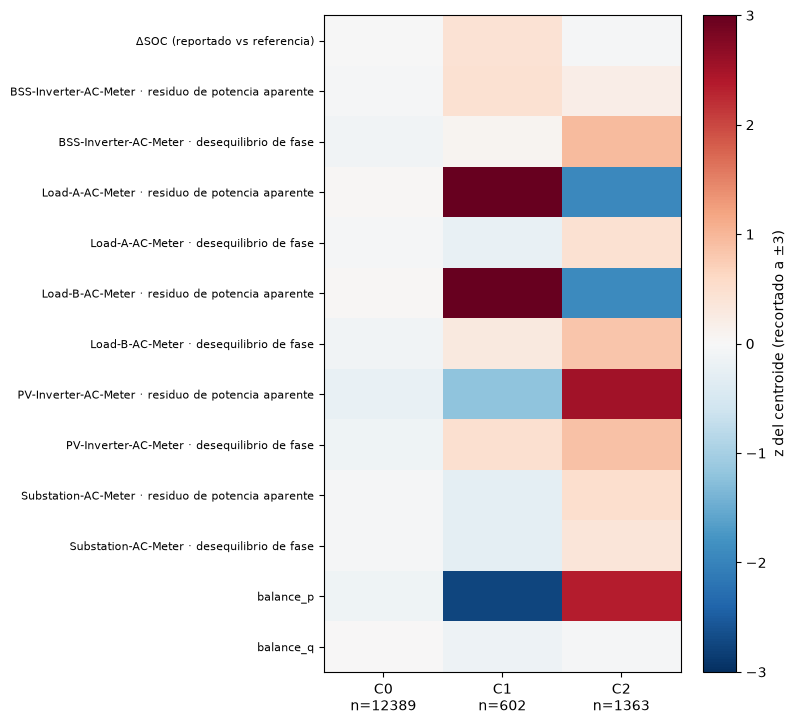

In [27]:

from src2.interpretationNS import nombre_legible, zscore_columnas

Z_perfil = zscore_columnas(X_inv.to_numpy(dtype=float))
clusters = [c for c in np.unique(etiquetas) if c != -1]
perfil = np.vstack([np.nanmean(Z_perfil[etiquetas == c], axis=0) for c in clusters])

fig, eje = plt.subplots(figsize=(1.3 * len(clusters) + 4, 0.45 * len(X_inv.columns) + 1.5))
imagen = eje.imshow(perfil.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
eje.set_yticks(range(len(X_inv.columns)))
eje.set_yticklabels([nombre_legible(c) for c in X_inv.columns], fontsize=8)
eje.set_xticks(range(len(clusters)))
eje.set_xticklabels([f"C{c}\nn={int((etiquetas == c).sum())}" for c in clusters])
fig.colorbar(imagen, ax=eje, label="z del centroide (recortado a ±3)")
plt.tight_layout()
plt.show()

### 10.3 Caracterizacion de Clusters

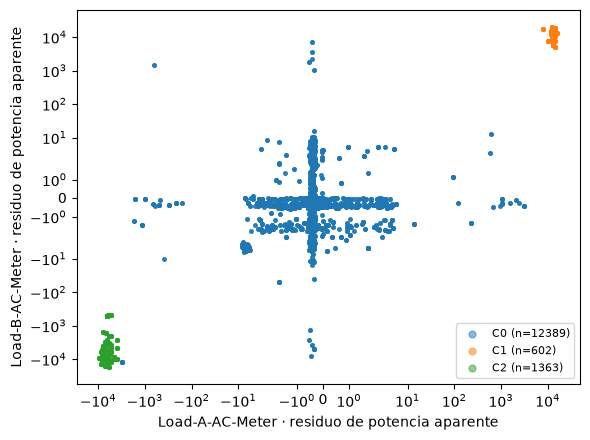

In [28]:
valores = X_inv.to_numpy(dtype=float)
orden = np.argsort(-np.abs(perfil).max(axis=0))
a, b = orden[0], orden[1]

fig, eje = plt.subplots(figsize=(6, 4.5))
for c in clusters:
    en = etiquetas == c
    eje.scatter(valores[en, a], valores[en, b], s=6, alpha=0.5,
                label=f"C{c} (n={int(en.sum())})")
eje.set_xscale("symlog")
eje.set_yscale("symlog")
eje.set_xlabel(nombre_legible(X_inv.columns[a]))
eje.set_ylabel(nombre_legible(X_inv.columns[b]))
eje.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

fuera del zoom ±5000: 2779 (19.4%) | de esos, ataques: 2596


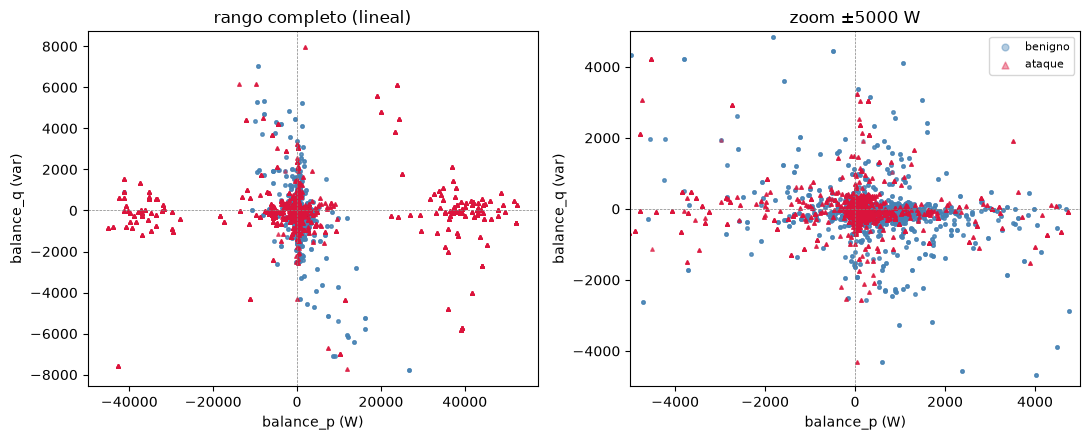

In [29]:

import numpy as np

valores = X_inv.to_numpy(dtype=float)
col_p = X_inv.columns.get_loc("balance_p")
col_q = X_inv.columns.get_loc("balance_q")

fig, (eje_ctx, eje_zoom) = plt.subplots(1, 2, figsize=(11, 4.5))
for eje in (eje_ctx, eje_zoom):
    for etiqueta, color, marca, nombre in [
        (0, "steelblue", "o", "benigno"),
        (1, "crimson", "^", "ataque"),
    ]:
        en = y_inv == etiqueta
        eje.scatter(valores[en, col_p], valores[en, col_q], s=6, alpha=0.4,
                    c=color, marker=marca, label=nombre)
    eje.axhline(0, color="gray", lw=0.5, ls="--")
    eje.axvline(0, color="gray", lw=0.5, ls="--")
    eje.set_xlabel("balance_p (W)")
    eje.set_ylabel("balance_q (var)")

eje_ctx.set_title("rango completo (lineal)")
lim = 5000
eje_zoom.set_xlim(-lim, lim)
eje_zoom.set_ylim(-lim, lim)
eje_zoom.set_title(f"zoom ±{lim} W")
eje_zoom.legend(markerscale=2, fontsize=8)

# Puntos que caen fuera del zoom, para no esconder los casos extremos.
fuera = (np.abs(valores[:, col_p]) > lim) | (np.abs(valores[:, col_q]) > lim)
print(f"fuera del zoom ±{lim}: {int(fuera.sum())} ({fuera.mean()*100:.1f}%) "
      f"| de esos, ataques: {int((fuera & (y_inv == 1)).sum())}")
plt.tight_layout()
plt.show()


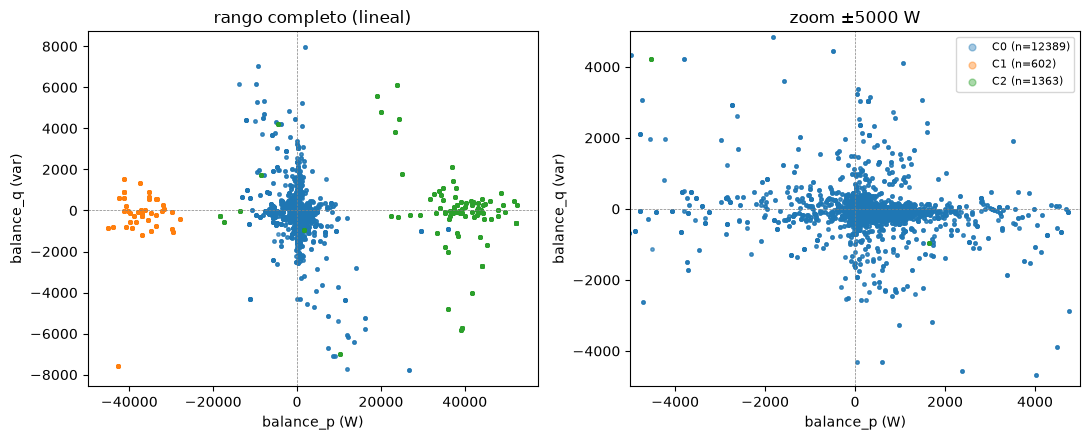

In [30]:

import numpy as np

valores = X_inv.to_numpy(dtype=float)
col_p = X_inv.columns.get_loc("balance_p")
col_q = X_inv.columns.get_loc("balance_q")
clusters = [c for c in np.unique(etiquetas) if c != -1]
colores = plt.get_cmap("tab10").colors

fig, (eje_ctx, eje_zoom) = plt.subplots(1, 2, figsize=(11, 4.5))
for eje in (eje_ctx, eje_zoom):
    for k, c in enumerate(clusters):
        en = etiquetas == c
        eje.scatter(valores[en, col_p], valores[en, col_q], s=6, alpha=0.4,
                    c=[colores[k % 10]], label=f"C{c} (n={int(en.sum())})")
    if -1 in etiquetas:
        en = etiquetas == -1
        eje.scatter(valores[en, col_p], valores[en, col_q], s=6, alpha=0.25,
                    c="lightgray", label=f"ruido (n={int(en.sum())})")
    eje.axhline(0, color="gray", lw=0.5, ls="--")
    eje.axvline(0, color="gray", lw=0.5, ls="--")
    eje.set_xlabel("balance_p (W)")
    eje.set_ylabel("balance_q (var)")

eje_ctx.set_title("rango completo (lineal)")
lim = 5000
eje_zoom.set_xlim(-lim, lim)
eje_zoom.set_ylim(-lim, lim)
eje_zoom.set_title(f"zoom ±{lim} W")
eje_zoom.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()


### 11. Detector: rango vs invariantes vs fusión

In [31]:

X_inv_por_escenario = {
    k: invariantes_fisicas(X[k]).reset_index(drop=True) for k in X
}

X_fusion_por_escenario = {
    k: pd.concat([X_rango[k].reset_index(drop=True), X_inv_por_escenario[k]], axis=1)
    for k in X
}

representaciones_detector = {
    "rango móvil 120 s": X_rango,
    "invariantes": X_inv_por_escenario,
    "rango + invariantes": X_fusion_por_escenario,
}


filas_detector = []
for nombre, X_rep in representaciones_detector.items():
    tabla = loso(X_rep, Y, "birch")
    resumen = tabla.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean().iloc[0]
    filas_detector.append({
        "representación": nombre,
        "features": X_rep["S1"].shape[1],
        "AUC": resumen["auc"],
        "recall@5": resumen["recall_5"],
        "recall": resumen["recall"],
        "espec S0": float(tabla.loc[tabla["escenario"] == "S0", "especificidad"].iloc[0]),
    })

comparacion_detector = pd.DataFrame(filas_detector).set_index("representación")
display(comparacion_detector.round(3))


,features,AUC,recall@5,recall,espec S0
representación,,,,,
rango móvil 120 s,132,0.778,0.312,0.311,1.000
invariantes,13,0.796,0.392,0.557,0.954
rango + invariantes,145,0.790,0.398,0.326,0.993


In [ ]:
# === 11.1 Detector Birch sobre invariantes: detección por escenario ===
tabla_birch_inv = loso(X_inv_por_escenario, Y, "birch").set_index("escenario")

deteccion_birch_inv = tabla_birch_inv.rename(columns={
    "n": "filas",
    "positivos": "ataques",
    "auc": "AUC",
    "recall_5": "recall@5%",
    "recall": "recall",
    "especificidad": "especificidad",
    "umbral": "umbral",
    "flagged": "marcadas",
})[["filas", "ataques", "AUC", "recall@5%", "recall", "especificidad", "umbral", "marcadas"]]

display(deteccion_birch_inv.round(3))

con_ataque = deteccion_birch_inv[deteccion_birch_inv["ataques"] > 0]
print(
    f"Birch sobre invariantes | AUC media: {con_ataque['AUC'].mean():.3f} | "
    f"recall@5% media: {con_ataque['recall@5%'].mean():.3f} | "
    f"recall media: {con_ataque['recall'].mean():.3f} | "
    f"especificidad S0: {deteccion_birch_inv.loc['S0', 'especificidad']:.3f}"
)
